In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
 
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

# Allow imports from the project folder
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

# Import our shared feature extraction functions
from utils.features import (
    load_audio,
    extract_mfcc,
    extract_chroma,
    extract_spectral_centroid,
    extract_zero_crossing_rate,
    compress_features,
)
 #Check if imported successfully
print("All imports successful!")
print("Project folder:", root)

All imports successful!
Project folder: /Users/simonedemir/Downloads/DT2470_Project


In [2]:
 
data_dir = root / "dataset_discriminator"
 
train_df = pd.read_csv(data_dir / "train.csv")
valid_df = pd.read_csv(data_dir / "valid.csv")
test_df = pd.read_csv(data_dir / "test.csv")
 
print("Training samples:", len(train_df))
print("Validation samples:", len(valid_df))
print("Test samples:", len(test_df))
 
display(train_df.head())

Training samples: 652
Validation samples: 136
Test samples: 156


,clip_id,audio_path,label,split,track_id,group_id,pair_id,genre,source,start_seconds,duration_seconds,sample_rate,channels,pcm_sha256,original_rms_dbfs,gain_db
0,dd137d69e55439b13820,audio/dd137d69e55439b13820.wav,1,train,fake_53707_udio_0,ai_prompt_53707,pair_0011,folk_country,udio,15,30,44100,1,2a061e91c4918755cf16e657b8228b4955c1ab899ac315...,-21.052,-1.948
1,df3d0f4170e7ee7297ee,audio/df3d0f4170e7ee7297ee.wav,1,train,fake_54112_suno_0,ai_prompt_54112,pair_0119,pop,suno,15,30,44100,1,a27707763ee6bbd5411101f3f3d7bec6d2162b6fd06944...,-17.638,-5.362
2,63be5d4153b83f9aa8ce,audio/63be5d4153b83f9aa8ce.wav,1,train,fake_53375_suno_1,ai_prompt_53375,pair_0015,electronic,suno,60,30,44100,1,eda28c027974c692a6ab56b126af78298295853e506934...,-17.758,-5.242
3,7375255eeb3b98ad2d12,audio/7375255eeb3b98ad2d12.wav,0,train,human_364087,human_artist_artist_007063,pair_0125,rock,jamendo,15,30,44100,1,94ca65b41bd91dd51d32273be6e58e58a2365940738955...,-8.295,-14.705
4,ba13a14364bda300fec5,audio/ba13a14364bda300fec5.wav,1,train,fake_54086_udio_0,ai_prompt_54086,pair_0216,electronic,udio,60,30,44100,1,6496cb7d24ea877a0c85358bb1dfd1e11dec35afd46c26...,-15.830,-7.170


In [4]:
def extract_svm_features(audio_path):
    
    y, sr = load_audio(audio_path)

    # Extract features
    mfcc = extract_mfcc(y, sr)
    chroma = extract_chroma(y, sr)
    centroid = extract_spectral_centroid(y, sr)
    zcr = extract_zero_crossing_rate(y, sr)

    # Combine compressed features
    return np.concatenate([
        compress_features(mfcc),
        compress_features(chroma),
        compress_features(centroid),
        compress_features(zcr)
    ])



Feature matrix shape: (5, 68)


In [5]:
# Directory for cached SVM features
cache_dir = root / "artifacts" / "svm_features"
cache_dir.mkdir(parents=True, exist_ok=True)

def build_feature_matrix(df, split_name):
    cache_file = cache_dir / f"{split_name}_features.npz"

    # Reuse previously extracted features
    if cache_file.exists():
        print(f"Loading cached {split_name} features...")
        cached = np.load(cache_file)
        return cached["X"], cached["y"]

    X = []
    y = []

    for i, (_, row) in enumerate(df.iterrows(), start=1):
        audio_path = data_dir / row["audio_path"]

        features = extract_svm_features(audio_path)

        X.append(features)
        y.append(int(row["label"]))

        if i % 25 == 0 or i == len(df):
            print(f"{split_name}: {i}/{len(df)} clips processed")

    X = np.asarray(X)
    y = np.asarray(y)

    np.savez_compressed(cache_file, X=X, y=y)
    print(f"Saved {split_name} features to {cache_file}")

    return X, y


X_train, y_train = build_feature_matrix(train_df, "train")
X_valid, y_valid = build_feature_matrix(valid_df, "valid")
X_test, y_test = build_feature_matrix(test_df, "test")

print("\nFinal shapes:")
print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)
print("Test:", X_test.shape, y_test.shape)

train: 25/652 clips processed
train: 50/652 clips processed
train: 75/652 clips processed
train: 100/652 clips processed
train: 125/652 clips processed
train: 150/652 clips processed
train: 175/652 clips processed
train: 200/652 clips processed
train: 225/652 clips processed
train: 250/652 clips processed
train: 275/652 clips processed
train: 300/652 clips processed
train: 325/652 clips processed
train: 350/652 clips processed
train: 375/652 clips processed
train: 400/652 clips processed
train: 425/652 clips processed
train: 450/652 clips processed
train: 475/652 clips processed
train: 500/652 clips processed
train: 525/652 clips processed
train: 550/652 clips processed
train: 575/652 clips processed
train: 600/652 clips processed
train: 625/652 clips processed
train: 650/652 clips processed
train: 652/652 clips processed
Saved train features to /Users/simonedemir/Downloads/DT2470_Project/artifacts/svm_features/train_features.npz
valid: 25/136 clips processed
valid: 50/136 clips proces

In [6]:
from sklearn.preprocessing import StandardScaler

# Check that all extracted features are valid
print("Train contains only finite values:", np.isfinite(X_train).all())
print("Validation contains only finite values:", np.isfinite(X_valid).all())
print("Test contains only finite values:", np.isfinite(X_test).all())

# Standardize features
scaler = StandardScaler()
 
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)

print("\nScaled feature shapes:")
print("Train:", X_train_scaled.shape)
print("Validation:", X_valid_scaled.shape)

print("\nMean of first feature:", round(X_train_scaled[:, 0].mean(), 6))
print("Std of first feature:", round(X_train_scaled[:, 0].std(), 6))

Train contains only finite values: True
Validation contains only finite values: True
Test contains only finite values: True

Scaled feature shapes:
Train: (652, 68)
Validation: (136, 68)

Mean of first feature: 0.0
Std of first feature: 1.0


In [7]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Create an SVM classifier with an RBF kernel
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale")

# Train the model using training data
svm_model.fit(X_train_scaled, y_train)

# Predict on validation data
y_valid_pred = svm_model.predict(X_valid_scaled)

# Evaluate the model
accuracy = accuracy_score(y_valid, y_valid_pred)

print("Validation accuracy:", round(accuracy, 4))
print("\nClassification report:")
print(classification_report(
    y_valid,
    y_valid_pred,
    target_names=["Human", "AI"]
))

print("Confusion matrix:")
print(confusion_matrix(y_valid, y_valid_pred))

Validation accuracy: 1.0

Classification report:
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00        68
          AI       1.00      1.00      1.00        68

    accuracy                           1.00       136
   macro avg       1.00      1.00      1.00       136
weighted avg       1.00      1.00      1.00       136

Confusion matrix:
[[68  0]
 [ 0 68]]


In [8]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix

# Train a linear SVM for comparison
linear_svm = SVC(kernel="linear", C=1.0)
linear_svm.fit(X_train_scaled, y_train)

# Predict validation labels
y_valid_linear = linear_svm.predict(X_valid_scaled)

# Compare the models
print("RBF SVM accuracy:",
      accuracy_score(y_valid, y_valid_pred))

print("Linear SVM accuracy:",
      accuracy_score(y_valid, y_valid_linear))

print("\nLinear SVM confusion matrix:")
print(confusion_matrix(y_valid, y_valid_linear))

RBF SVM accuracy: 1.0
Linear SVM accuracy: 1.0

Linear SVM confusion matrix:
[[68  0]
 [ 0 68]]


In [9]:
# Feature groups based on our extraction order
feature_groups = {
    "MFCC": (0, 40),
    "Chroma": (40, 64),
    "Spectral centroid": (64, 66),
    "Zero-crossing rate": (66, 68),
}

results = []

for feature_name, (start, end) in feature_groups.items():

    # Select one feature group
    X_train_group = X_train[:, start:end]
    X_valid_group = X_valid[:, start:end]

    # Standardize using training data only
    group_scaler = StandardScaler()
    X_train_group = group_scaler.fit_transform(X_train_group)
    X_valid_group = group_scaler.transform(X_valid_group)

    # Train a linear SVM
    model = SVC(kernel="linear", C=1.0)
    model.fit(X_train_group, y_train)

    # Evaluate on validation data
    predictions = model.predict(X_valid_group)
    accuracy = accuracy_score(y_valid, predictions)

    results.append({
        "Feature": feature_name,
        "Number of features": end - start,
        "Accuracy": accuracy
    })

results_df = pd.DataFrame(results)

display(results_df)

,Feature,Number of features,Accuracy
0,MFCC,40,1.000000
1,Chroma,24,0.727941
2,Spectral centroid,2,0.933824
3,Zero-crossing rate,2,0.654412


As shown in the table above, MFCC achieves an accuracy of 1. Therefore, we investigate MFCC further by comparing the mean of the first MFCC coefficients between humans and AI below.

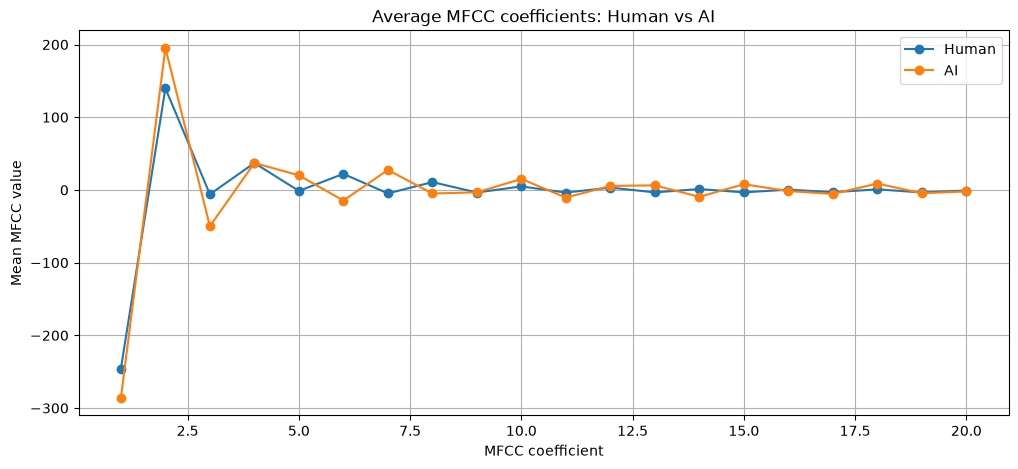

In [10]:
import matplotlib.pyplot as plt

# MFCC mean features occupy indices 0-19
mfcc_human = X_train[y_train == 0, :20]
mfcc_ai = X_train[y_train == 1, :20]

# Average each coefficient across all training clips
human_mean = mfcc_human.mean(axis=0)
ai_mean = mfcc_ai.mean(axis=0)

plt.figure(figsize=(12, 5))

plt.plot(range(1, 21), human_mean, marker="o", label="Human")
plt.plot(range(1, 21), ai_mean, marker="o", label="AI")

plt.xlabel("MFCC coefficient")
plt.ylabel("Mean MFCC value")
plt.title("Average MFCC coefficients: Human vs AI")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
# Compare standardized differences between MFCC coefficients

mfcc_human = X_train[y_train == 0, :20]
mfcc_ai = X_train[y_train == 1, :20]

human_mean = mfcc_human.mean(axis=0)
ai_mean = mfcc_ai.mean(axis=0)

human_var = mfcc_human.var(axis=0, ddof=1)
ai_var = mfcc_ai.var(axis=0, ddof=1)

# Pooled standard deviation
pooled_std = np.sqrt((human_var + ai_var) / 2)

# Standardized mean difference
effect_size = np.divide(
    ai_mean - human_mean,
    pooled_std,
    out=np.zeros_like(ai_mean),
    where=pooled_std > 0
)

effect_df = pd.DataFrame({
    "MFCC": np.arange(1, 21),
    "Effect size": effect_size,
    "Absolute effect size": np.abs(effect_size)
})

display(
    effect_df.sort_values(
        "Absolute effect size",
        ascending=False
    ).head(10)
)

,MFCC,Effect size,Absolute effect size
5,6,-4.730554,4.730554
6,7,3.384280,3.384280
7,8,-2.589164,2.589164
13,14,-2.531151,2.531151
4,5,2.437822,2.437822
1,2,2.360950,2.360950
14,15,2.245295,2.245295
12,13,1.882138,1.882138
17,18,1.740861,1.740861
2,3,-1.681535,1.681535


In [12]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Scale the test data using the training scaler
X_test_scaled = scaler.transform(X_test)

# Predict using the RBF SVM
y_test_pred = svm_model.predict(X_test_scaled)

# Evaluation metrics
accuracy = accuracy_score(y_test, y_test_pred)
precision = precision_score(y_test, y_test_pred)
recall = recall_score(y_test, y_test_pred)
f1 = f1_score(y_test, y_test_pred)

# False positive rate
tn, fp, fn, tp = confusion_matrix(
    y_test, y_test_pred, labels=[0, 1]
).ravel()

fpr = fp / (fp + tn)

print("Final SVM Test Results")
print("----------------------")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"False positive rate: {fpr:.4f}")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_test_pred))

Final SVM Test Results
----------------------
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-score: 1.0000
False positive rate: 0.0000

Confusion matrix:
[[78  0]
 [ 0 78]]
